# Adelaide on the shortest day: hours of sun on every street and park

Hours of direct sun on 21 June 2026, from 9 am to 3 pm Adelaide time, along every street and over every park in the City
of Adelaide, with the 7,341 buildings at their heights casting the shadows. The hours were worked out in
[Plotlay](https://www.getplotlay.com) with Sun and shade on a 1 m grid, the sun's position every 15 minutes.

This notebook reads only the files in `../data`.

**Read it carefully.** Direct sun only: no light from the sky, no reflections off buildings, no cloud, and the ground
taken as level. Verandahs, awnings and trees are not modelled. Accuracy depends on the building heights and the data;
about one height in ten is an estimate. This is not a certified solar access or overshadowing assessment.

In [1]:
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
DATA = '../data'
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
seg = gpd.read_file(f'{DATA}/street_segments.geojson')
print(len(seg), 'street parts;', round(seg.metres.sum() / 1000, 1), 'km of street sampled every metre')
seg.head()

1767 street parts; 175.1 km of street sampled every metre


,osm_id,name,highway,metres,mean_h,under_2h_pct,runs,built_up_m,built_up_hours,built_up_under_2h_m,built_up_under_1h_m,geometry
0,w4613905,Frome Road,secondary,31,6.00,0.0,north-south,17,102.00,0,0,"LINESTRING (138.60204 -34.91192, 138.60185 -34..."
1,w4638166,Hindley Street,tertiary,20,6.00,0.0,east-west,20,120.00,0,0,"LINESTRING (138.58732 -34.9236, 138.58754 -34...."
2,w4638183,Franklin Street,tertiary,22,6.00,0.0,east-west,22,132.00,0,0,"LINESTRING (138.58762 -34.92776, 138.58786 -34..."
3,w4638206,NaN,primary,22,5.85,0.0,east-west,22,128.75,0,0,"LINESTRING (138.58773 -34.92919, 138.58797 -34..."
4,w4638212,Morphett Street,secondary,125,5.73,0.0,north-south,125,716.50,0,0,"LINESTRING (138.59383 -34.92777, 138.59384 -34..."


## The built-up streets

Each street part was sampled every metre along its middle (roofs left out, where a street passes under a building).
The **built-up** samples are those within 40 m of a building: the two street grids, not the roads across the Park
Lands. `built_up_m` counts them, `built_up_hours` adds up their hours, `built_up_under_2h_m` counts those under 2 hours.

In [2]:
bu = seg[seg.built_up_m > 0]
def share(d):
    m = d.built_up_m.sum()
    return pd.Series({'km': round(m / 1000, 1), 'mean hours': round(d.built_up_hours.sum() / m, 2),
                      'under 2 h %': round(100 * d.built_up_under_2h_m.sum() / m, 1), 'under 1 h %': round(100 * d.built_up_under_1h_m.sum() / m, 1)})
tab = pd.concat({'all built-up streets': share(bu), 'east-west': share(bu[bu.runs == 'east-west']), 'north-south': share(bu[bu.runs == 'north-south'])}, axis=1).T
tab

,km,mean hours,under 2 h %,under 1 h %
all built-up streets,142.6,3.86,22.9,15.1
east-west,70.7,3.62,29.9,22.6
north-south,71.9,4.09,16.1,7.7


Light's grid runs almost exactly east-west and north-south. In winter the sun stays low in the north, so the buildings
on the north side of an east-west street throw their shadow across it for most of the day. A north-south street gets
sun down its length around noon.

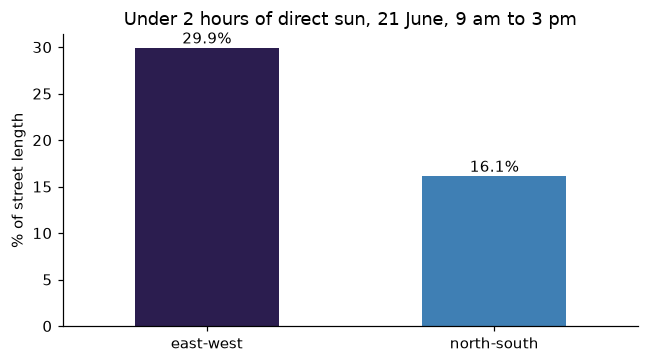

In [3]:
ax = tab.loc[['east-west', 'north-south'], 'under 2 h %'].plot.bar(color=['#2b1d4f', '#3f7fb4'], rot=0, figsize=(6, 3.4))
ax.set_ylabel('% of street length'); ax.set_title('Under 2 hours of direct sun, 21 June, 9 am to 3 pm')
for i, v in enumerate(tab.loc[['east-west', 'north-south'], 'under 2 h %']): ax.text(i, v + 0.5, f'{v}%', ha='center')
plt.tight_layout()

## Street by street

`streets.csv` joins the parts of each named street in the built-up grids. The long streets (500 m or more) with the
least sun:

In [4]:
st = pd.read_csv(f'{DATA}/streets.csv')
st[st.metres >= 500].sort_values('mean_h').head(10)[['name', 'metres', 'mean_h', 'under_2h_pct', 'runs']]

,name,metres,mean_h,under_2h_pct,runs
6,Rundle Mall,549,0.17,100.0,east-west
64,Gawler Place,766,1.57,75.8,north-south
70,Ifould Street,556,1.69,68.2,east-west
71,Hindley Street,1124,1.72,66.0,east-west
82,Grenfell Street,1921,1.86,56.5,east-west
86,Franklin Street,1651,1.94,60.6,east-west
89,Flinders Street,1742,1.95,59.5,east-west
95,Pirie Street,1088,2.02,60.6,east-west
107,Waymouth Street,1126,2.18,51.2,east-west
122,Kermode Street,538,2.48,45.7,east-west


In [5]:
print((st.under_2h_pct > 50).sum(), 'of', len(st), 'named streets get under 2 hours along more than half their built-up length')

102 of 379 named streets get under 2 hours along more than half their built-up length


## Parks and squares

OpenStreetMap's parks, gardens and squares in the council area, with the mean hours over their ground. The five squares
of Light's plan, and Victoria Square in the middle:

In [6]:
pk = pd.read_csv(f'{DATA}/parks.csv')
pk[pk.name.str.contains('Square')].sort_values('mean_h')[['name', 'area_m2', 'mean_h', 'under_2h_pct']]

,name,area_m2,mean_h,under_2h_pct
8,Hindmarsh Square,13209,4.14,17.4
11,Victoria Square/Tartanyangga,44834,5.03,0.8
13,Whitmore Square,24196,5.29,1.3
19,Hurtle Square,18184,5.73,0.0
20,Light Square,12846,5.79,0.0
48,Wellington Square,27292,5.99,0.0


## The grid itself

`sun_hours_2m.tif` is the hours on the ground in 2 m cells (each the mean of four 1 m cells), in WGS 84 / UTM zone 54S
(EPSG:32754), roofs as no data. It opens in QGIS or ArcGIS as it is. Here it is read with the standard library and numpy
only, so the notebook needs no GDAL.

In [7]:
import numpy as np, struct, zlib
def read_tiff(path):
    b = open(path, 'rb').read(); le = b[:2] == b'II'; E = '<' if le else '>'
    off = struct.unpack(E + 'I', b[4:8])[0]; n = struct.unpack(E + 'H', b[off:off + 2])[0]; tags = {}
    size = {1: 1, 2: 1, 3: 2, 4: 4, 5: 8, 11: 4, 12: 8, 16: 8}; fmt = {1: 'B', 2: 'c', 3: 'H', 4: 'I', 11: 'f', 12: 'd', 16: 'Q'}
    for i in range(n):
        t, ty, cnt, val = struct.unpack(E + 'HHI4s', b[off + 2 + 12 * i: off + 14 + 12 * i])
        raw = val if size[ty] * cnt <= 4 else b[struct.unpack(E + 'I', val)[0]:][:size[ty] * cnt]
        tags[t] = raw if ty == 2 else struct.unpack(E + fmt[ty] * cnt, raw[:size[ty] * cnt]) if ty != 5 else raw
    W, H = tags[256][0], tags[257][0]; rows = tags[278][0]; comp = tags[259][0]; pred = tags.get(317, (1,))[0]
    out = bytearray()
    for o, c in zip(tags[273], tags[279]):
        s = b[o:o + c]; s = zlib.decompress(s) if comp in (8, 32946) else s
        if pred == 3:   # the floating point predictor: undo the byte differencing, then put the bytes back in order
            nr = len(s) // (W * 4); a = np.frombuffer(s, np.uint8).reshape(nr, 4 * W).cumsum(axis=1).astype(np.uint8)
            s = a.reshape(nr, 4, W).transpose(0, 2, 1)[:, :, ::-1 if le else 1].tobytes()
        out += s
    a = np.frombuffer(bytes(out), E + 'f4')[:W * H].reshape(H, W).astype(float)
    a[a == -9999] = np.nan
    sx, sy = tags[33550][:2]; e0, n0 = tags[33922][3], tags[33922][4]
    return a, (e0, sx, n0, -sy)
g, gt = read_tiff(f'{DATA}/sun_hours_2m.tif')
print(g.shape, 'cells of', gt[1], 'm; ground cells', np.isfinite(g).sum())

(2502, 2266) cells of 2.0 m; ground cells 4804451


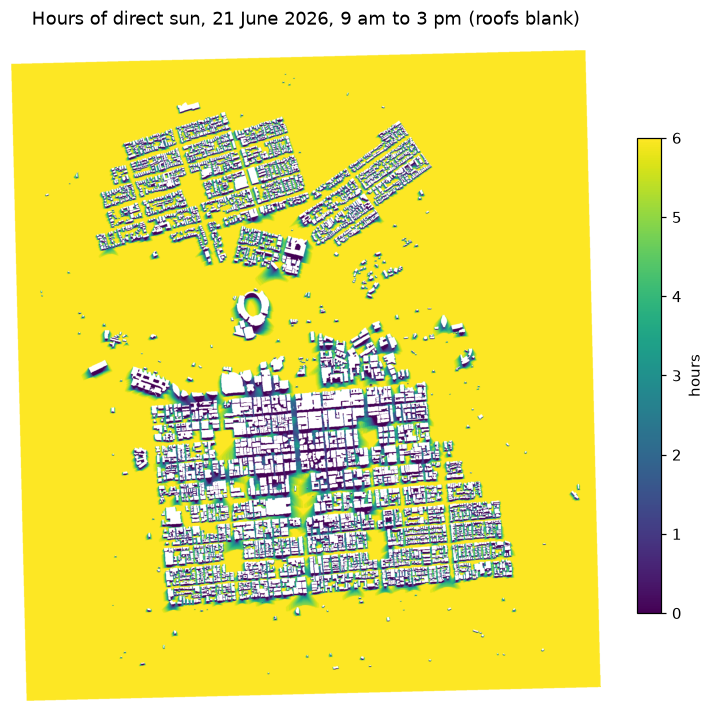

In [8]:
fig, ax = plt.subplots(figsize=(7, 7.5))
im = ax.imshow(g, cmap='viridis', vmin=0, vmax=6, extent=(gt[0], gt[0] + g.shape[1] * gt[1], gt[2] + g.shape[0] * gt[3], gt[2]))
ax.set_title('Hours of direct sun, 21 June 2026, 9 am to 3 pm (roofs blank)'); ax.set_axis_off()
plt.colorbar(im, ax=ax, shrink=0.6, label='hours'); plt.tight_layout()

The street numbers above come from the 1 m grid, sampled along each street; this 2 m grid is for maps and GIS.